# W10. Affective computing

**Wersja źródła:** 1.1.9 · **Data:** 2026-11-04

In [ ]:
import numpy as np
rng = np.random.default_rng(17)
grupy = np.repeat(np.arange(60), 4)
indywidualne = rng.normal(0, .7, 60)[grupy]
stan = rng.normal(size=len(grupy)) + .5 * indywidualne
glos = 170 + 25 * stan + rng.normal(0, 20, len(grupy))
eda = 1.5 + .4 * stan + rng.normal(0, .4, len(grupy))
y = (stan + rng.normal(0, .8, len(grupy)) > .2).astype(int)
X = np.column_stack([glos, eda])
print("Wirtualni uczestnicy:", len(np.unique(grupy)))


Wirtualni uczestnicy: 60


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, f1_score
split = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=42)
tr, te = next(split.split(X, y, groups=grupy))
assert set(grupy[tr]).isdisjoint(set(grupy[te]))
print("Uczestnicy trening / test:", len(set(grupy[tr])), len(set(grupy[te])))


Uczestnicy trening / test: 45 15


In [ ]:
from sklearn.model_selection import GroupKFold, cross_val_score
cv = GroupKFold(n_splits=5)
for nazwa, kolumny in {"Głos":[0], "EDA":[1], "Fuzja":[0, 1]}.items():
    est = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    cv_auc = cross_val_score(est, X[np.ix_(tr, kolumny)], y[tr],
        groups=grupy[tr], cv=cv, scoring="roc_auc")
    print(nazwa, "CV ROC-AUC:", np.round(cv_auc, 3))


Głos CV ROC-AUC: [0.625 0.76  0.767 0.672 0.825]
EDA CV ROC-AUC: [0.585 0.792 0.587 0.712 0.662]
Fuzja CV ROC-AUC: [0.628 0.774 0.726 0.693 0.825]


In [ ]:
wyniki = {}
for nazwa, kolumny in {"Głos":[0], "EDA":[1], "Fuzja":[0, 1]}.items():
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(X[np.ix_(tr, kolumny)], y[tr])
    pred = model.predict_proba(X[np.ix_(te, kolumny)])[:, 1]
    wyniki[nazwa] = roc_auc_score(y[te], pred)
    print(nazwa, "F1:", round(f1_score(y[te], pred >= .5), 3))
print({k: round(v, 3) for k, v in wyniki.items()})


Głos F1: 0.651
EDA F1: 0.571
Fuzja F1: 0.698
{'Głos': 0.83, 'EDA': 0.767, 'Fuzja': 0.846}


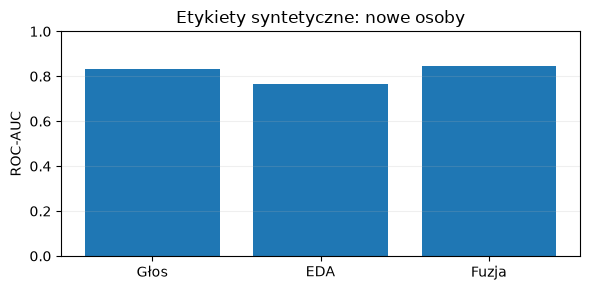

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(list(wyniki), list(wyniki.values()))
ax.set(ylim=(0, 1), ylabel="ROC-AUC", title="Etykiety syntetyczne: nowe osoby")
ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()
